# Project : Internal heat exchanger (IHX)

### imports

In [4]:
# --- imports ---
import numpy as np
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary
from caldis.components import Compressor
from caldis.components import SizingHX
from caldis.components import Valve
from caldis.fluids import CoolPropBackend
from caldis.solvers import solve


print("Caldis version:", getattr(caldis, "__version__", "unknown"))

Caldis version: 0.4.1


## The baseline cycle — S0

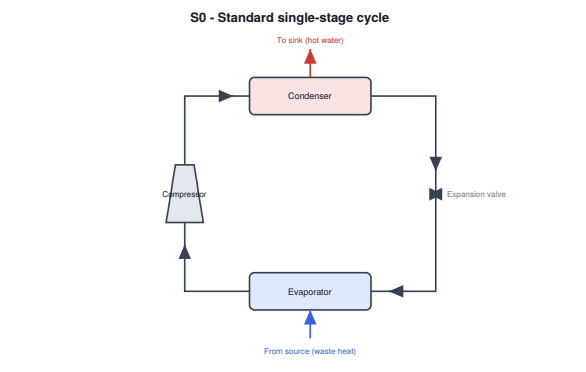

In [ ]:
# Common specification and assumptions

p_sink = 10e5 # 10 bar, condenser
T_cond_w_in = 120 + 273.15
T_cond_w_out = 130 + 273.15

p_source = 3e5 # 3 bar, evaporator
T_evap_w_in = 35 + 273.15
T_evap_w_out = 30 + 273.15

P_heating = 100e3 # condensor

sc = 5 # supercooling at evaporator outlet
sh = 5 # superheating at condenser outlet

pinch = 5 # 5K, evaporator and condenser

eta_is = 0.70

In [10]:
# Saturation temperatures and pressures for refrigerant

p_cond = PropsSI("P", "T", T_cond_w_out + pinch, "Q", 1, "R-1233zd(E)")
p_evap = PropsSI("P", "T", T_evap_w_out - pinch, "Q", 1, "R-1233zd(E)")

print("p_cond = ", p_cond/1e5, "bar")
print("p_evap = ", p_evap/1e5, "bar")

p_cond =  20.98742181543876 bar
p_evap =  1.303364949364911 bar


Dans le condenseur : $P_h = m_e \times c_{p,e} \times \Delta T$

In [14]:
# Determine the mass flow rate of the water circuit

h_cond_w_in = PropsSI("H", "P", p_sink, "T", T_cond_w_in, "Water")
h_cond_w_out = PropsSI("H", "P", p_sink, "T", T_cond_w_out, "Water")
mdot_w = P_heating / (h_cond_w_out - h_cond_w_in)
print("mdot_w =", mdot_w, "kg/s")

mdot_w = 2.3528134490879387 kg/s


In [15]:
# Determine the mass flow rate of the refregierant circuit 

#??????????????????????????

In [ ]:
# Etape Evap
be_r = CoolPropBackend("R-1233zd(E)") # on définit que le réfrigérant c'est du R-1233zd(E)
mdot_r = 0.03
eta_is = 0.85

be_w = CoolPropBackend('Water') # on définit que la source chaude à chauffer c'est de l'eau
h_hot = 2500
h_cold = 3000

# Déclarer les composants
compressor = Compressor("compressor", backend=be_r, eta_is=eta_is)
condensor = SizingHX('condensor', backend_cold=be_w, backend_hot=be_r, 
                h_cold=h_cold, h_hot=h_hot,
                area_ratio_cold_to_hot=1)
source_w = FluidBoundary('source_w', backend=be_w, 
                         p=p_w, T=T_w_in)
sink_w = FluidBoundary('sink_w', backend=be_w, T=T_w_out)
valve = Valve('valve', backend=be_r)

be_a = CoolPropBackend('Air')
evaporator = SizingHX('evaporator', backend_cold=be_r, backend_hot=be_a, 
                h_cold=2500, h_hot=50,
                area_ratio_cold_to_hot=1/15)
p_a = 1e5
source_a = FluidBoundary('source_a', backend=be_a, p=p_a, T=T_a_in)
sink_a = FluidBoundary('sink_a', backend=be_a, T=T_a_out)

# Déclarer le système
sys_ = System('sys')

# Ajouter les composants
sys_.add(comp, source_w, sink_w, cond, valve, evap, source_a, sink_a)

# Ajouter les connections entre les composants
sys_.connect(comp.out, cond.hot_in)
sys_.connect(cond.hot_out, valve.inl)
sys_.connect(cond.cold_in, source_w.port)
sys_.connect(cond.cold_out, sink_w.port)
sys_.connect(valve.out, evap.cold_in)
sys_.connect(evap.cold_out, comp.inl, close_loop=True)
sys_.connect(evap.hot_in, source_a.port)
sys_.connect(evap.hot_out, sink_a.port)


# Contraintes
sys_.add_constraint(lambda: (sink_w.port.h - source_w.port.h)*sink_w.port.mdot - P_heating, 'P_heating')
sys_.add_constraint(lambda: cond.hot_out.T -(T_cd-sc), 'SC')
sys_.add_constraint(lambda: valve.inl.p - p_cd, 'HP')
sys_.add_constraint(lambda: valve.out.p - p_ev, 'LP')
sys_.add_constraint(lambda: comp.inl.T - (T_ev+sh), 'Superheat')

sys_.set_start_port(cond.hot_in, p=p_cd, T=T_cd+10)
sys_.set_start_port(cond.hot_out, p=p_cd, T=T_cd-sc)
sys_.set_start_port(cond.cold_in, p=p_w, T=T_w_in)
sys_.set_start_port(cond.cold_out, p=p_w, T=T_w_out)

# # These starts helps converge faster
# sys_.set_start_port(evap.cold_in, p=p_ev, T=T_ev-1)
# sys_.set_start_port(evap.cold_out, p=p_ev, T=T_ev+sh)
# sys_.set_start_port(evap.hot_in, p=p_a, T=T_a_in)
# sys_.set_start_port(evap.hot_out, p=p_a, T=T_a_out)

from caldis.solvers.autostart import autostart
autostart(sys_)

sol = solve(sys_, verbose=True)

## Internal heat exchanger (IHX) - S4